# Notebook 7 — Merging & cleanup

*SWC ENC 2026 · ephys-pop module*

A sorter's raw output is rarely final. A common error is **over-splitting**: one neuron
gets divided into two "units" (say its bigger and smaller spikes fall in different
clusters). We need to catch that and **merge** them. The tools are spike **timing** and
spike **shape** — and we'll build the timing tool, the **correlogram**, from the ground
up.

**In this notebook you will:**
1. See a unit as a **spike train**, and build a **correlogram** by sliding one train past
   another.
2. Learn its two key readings — a flat *chance* level, and the **refractory hole**.
3. Diagnose an **over-split** and merge it; and see when *not* to merge.

*(For well-populated correlograms we use the **true** spike trains here — we know them,
and there are plenty. On real data you'd run these identical checks on your sorted units.)*

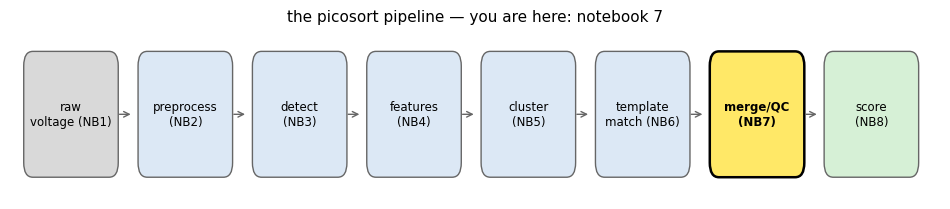

In [1]:
import matplotlib.pyplot as plt, picosort as ps
ps.plotting.draw_pipeline(highlight=7); plt.show()      # where we are in the pipeline

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import picosort as ps

# a longer, higher-rate recording so the spike trains are rich; we only need the
# filtered traces (for templates) and the true spike trains — no sorting required here.
rec = ps.make_recording(n_units=6, duration_s=60.0, rate_range=(8, 15), seed=0)
filtered = ps.common_average_reference(ps.highpass_filter(rec.traces, rec.fs))
fs = rec.fs
gt = rec.ground_truth
times, labels = gt.spike_times, gt.spike_labels

def template_of(spike_times):
    # average template of any set of spike times, from the filtered traces
    snippets, _ = ps.extract_snippets(filtered, spike_times, align=False)
    return snippets.mean(axis=0)

u = int(np.bincount(labels).argmax())          # a well-sampled unit to work with
t_u = times[labels == u]
print(f"{len(np.unique(labels))} units; unit {u} fired {len(t_u)} times in {rec.duration_s:.0f} s")

6 units; unit 2 fired 883 times in 60 s


## 1. A unit is a spike train

The end product of sorting is, for each unit, a **spike train** — the list of times it
fired. Drawn as a raster (one tick per spike), unit `u` looks like this:

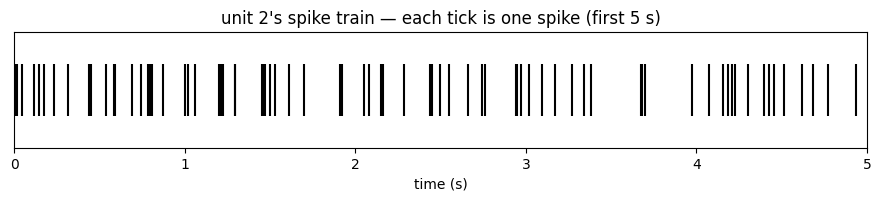

In [3]:
plt.figure(figsize=(11, 1.5))
plt.eventplot(t_u / fs, colors="k", lineoffsets=0, linelengths=1)
plt.xlim(0, 5); plt.yticks([]); plt.xlabel("time (s)")
plt.title(f"unit {u}'s spike train — each tick is one spike (first 5 s)")
plt.show()

Why would spike *timing* help us judge the sorting? Because a neuron obeys one hard
rule: after it fires, it needs a millisecond or two to recover — the **refractory
period** — before it can fire again. So in a single neuron's spike train, **no two
spikes are ever closer than that.** Check it on unit `u`: the histogram of gaps
between consecutive spikes.

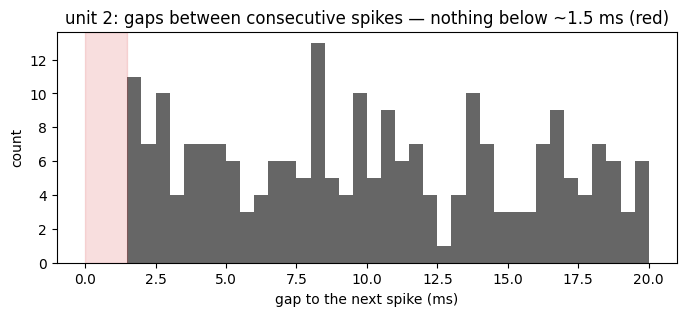

In [4]:
gaps_ms = np.diff(t_u) / fs * 1e3                    # gap between each spike and the next
plt.figure(figsize=(8, 3))
plt.hist(gaps_ms, bins=np.arange(0, 20.5, 0.5), color="0.4")
plt.axvspan(0, 1.5, color="tab:red", alpha=0.15)
plt.xlabel("gap to the next spike (ms)"); plt.ylabel("count")
plt.title(f"unit {u}: gaps between consecutive spikes — nothing below ~1.5 ms (red)")
plt.show()

The red zone is empty. That gives us a test. Suppose a sorter had split one neuron
into two units, **A** and **B**. Each would still have no short gaps on its own, so
each would look like a tidy neuron. But now look at the gaps *between* an A spike and
the nearest B spike. If A and B are really the **same** neuron, those gaps can't be
short either — the refractory rule applies to the neuron, not to our labels. If A and
B are **different** neurons, they fire independently, and now and then one will fire
within a millisecond of the other: no empty zone.

So "are A and B the same neuron?" becomes "are there any short A-to-B gaps?" The tool
that counts the gaps between two spike trains — at every separation, not just the
shortest — is the **correlogram**. Let's build it.

## 2. Building a correlogram: slide one train past the other

To compare two spike trains A and B, we ask: **at a given lag $\tau$, how many spikes
line up if we shift B by $\tau$?** Slide B along, and at each lag count the coincidences
(a B spike landing within one bin of an A spike). The plot of *count vs lag* is the
**correlogram**. Here it is on two tiny toy trains, at three example lags:

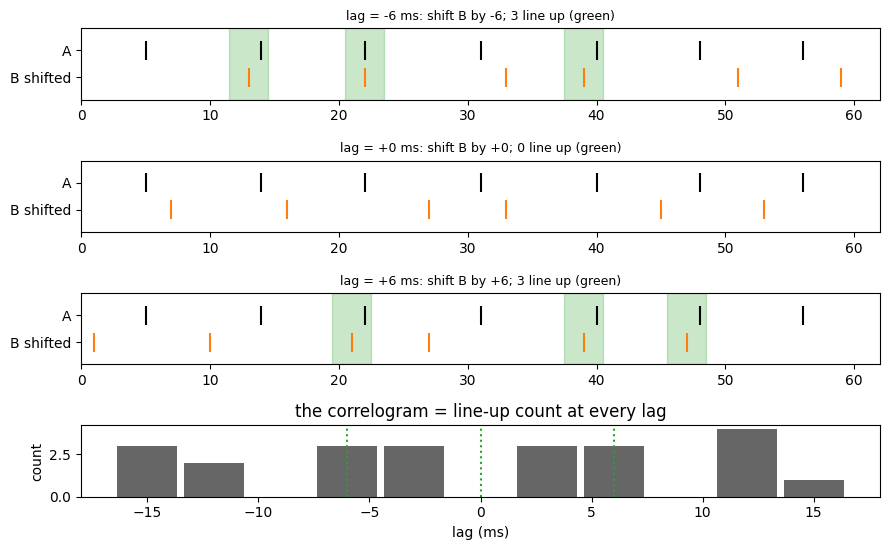

In [5]:
A = np.array([5, 14, 22, 31, 40, 48, 56], float)     # toy train A (times in ms)
B = np.array([7, 16, 27, 33, 45, 53], float)         # toy train B
bin_ms = 3.0

def count_lineups(A, B, lag, bin_ms):
    shifted = B - lag                                # a coincidence needs (b - a) == lag
    return [b for b in shifted if np.any(np.abs(A - b) < bin_ms / 2)]

show = [-6, 0, 6]
fig, axes = plt.subplots(len(show) + 1, 1, figsize=(9, 1.4 * (len(show) + 1)))
for ax, lag in zip(axes[:-1], show):
    shifted = B - lag
    ax.eventplot(A, colors="k", lineoffsets=1, linelengths=0.7)
    ax.eventplot(shifted, colors="tab:orange", lineoffsets=0, linelengths=0.7)
    for b in count_lineups(A, B, lag, bin_ms):
        ax.axvspan(b - bin_ms / 2, b + bin_ms / 2, color="tab:green", alpha=0.25)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["B shifted", "A"]); ax.set_xlim(0, 62)
    ax.set_title(f"lag = {lag:+d} ms: shift B by {lag:+d}; {len(count_lineups(A, B, lag, bin_ms))} line up (green)",
                 fontsize=9)
# the correlogram: repeat the count at every lag
lags = np.arange(-15, 16, bin_ms)
counts = [len(count_lineups(A, B, lag, bin_ms)) for lag in lags]
axes[-1].bar(lags, counts, width=bin_ms * 0.9, color="0.4")
for lag in show:
    axes[-1].axvline(lag, color="tab:green", ls=":")
axes[-1].set_title("the correlogram = line-up count at every lag"); axes[-1].set_xlabel("lag (ms)")
axes[-1].set_ylabel("count")
plt.tight_layout(); plt.show()

That's all a correlogram is: slide, count line-ups, repeat. A train compared with
*itself* is the **auto-correlogram** — the distribution of gaps between a unit's own
spikes (we skip lag 0, where every spike trivially matches itself).

<details>
<summary><b>▸ Go deeper: the flat baseline from Poisson statistics (optional)</b></summary>

Each unit is a **point process** — a random set of spike times. The cross-correlogram
estimates the **cross-intensity**: given a spike of unit A, the rate of unit B's spikes
at a lag $\tau$ later. If the two are **independent Poisson** processes with rates
$\lambda_A, \lambda_B$, the expected count in a bin of width $\Delta$ over a recording of
length $T$ is flat,

$$\mathbb{E}[\text{count at lag }\tau] \;=\; \lambda_A\,\lambda_B\,\Delta\,T,$$

independent of $\tau$. For an **auto**-correlogram of one train ($N$ spikes, rate
$\lambda = N/T$), each of the $N$ spikes expects $\lambda\Delta$ partners in a bin, so the
level is $N\lambda\Delta = \lambda^2 T \Delta$ — the chance line we draw below. The
**refractory hole** is the sharpest departure from it: a neuron's biophysics forbid a
second spike within $\sim$1–2 ms, so its auto-correlogram is pinned near zero at small
lags — something no pair of *distinct* neurons produces.
</details>

**Exercise 1** *(~7 min)*. Complete `correlogram` (the full version, over real spike times):
for each spike in `ta`, take the differences to the spikes of `tb` within `±window_ms`,
and accumulate them into a histogram. Return the bin centres (ms) and counts.

> **Check / unstuck.** The toy demos below should render (a flat line, and a hole). Stuck?
> Use `ps.correlogram(ta, tb, fs)`.

In [6]:
def correlogram(ta, tb, fs, bin_ms=0.5, window_ms=25.0, exclude_zero=False):
    ta = np.sort(ta) / fs * 1e3
    tb = np.sort(tb) / fs * 1e3
    edges = np.arange(-window_ms, window_ms + bin_ms, bin_ms)
    counts = np.zeros(len(edges) - 1)
    for t in ta:
        d = tb[(tb >= t - window_ms) & (tb <= t + window_ms)] - t
        if exclude_zero:
            d = d[np.abs(d) > 1e-9]
        counts += np.histogram(d, edges)[0]
    return (edges[:-1] + edges[1:]) / 2, counts

print("correlogram ready")

correlogram ready


## 3. The two readings: chance, and the refractory hole

Two toy trains make the readings concrete: a purely **random** (Poisson) train, and one
with a **refractory period** enforced (no spike within 2 ms of the last). We use lots of
spikes so the histograms are smooth.

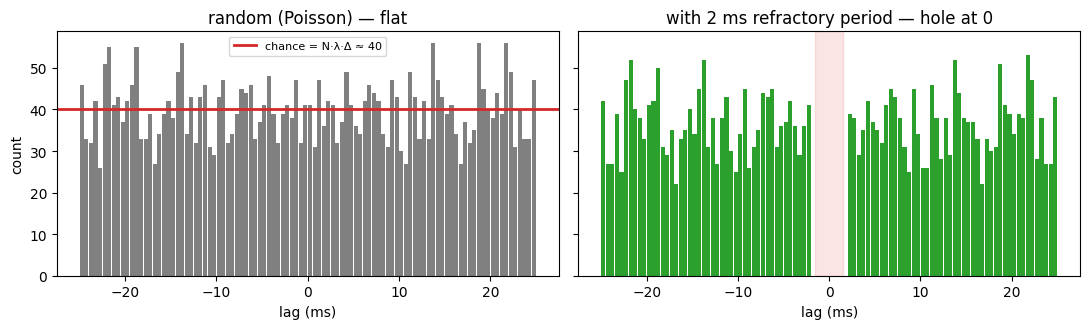

In [7]:
rng = np.random.default_rng(1)
T_toy, rate_toy = 200.0, 20.0                                   # 200 s at 20 Hz -> ~4000 spikes
random_train = np.sort(rng.integers(0, int(T_toy * fs), int(rate_toy * T_toy)))
refr = int(0.002 * fs)                                          # 2 ms refractory period
keep = [random_train[0]]
for t in random_train[1:]:
    if t - keep[-1] > refr:
        keep.append(t)
refractory_train = np.array(keep)

bin_ms = 0.5
expected = len(random_train) * (len(random_train) / T_toy) * (bin_ms / 1000)   # N·λ·Δ

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
c, n = correlogram(random_train, random_train, fs, bin_ms=bin_ms, exclude_zero=True)
ax[0].bar(c, n, width=bin_ms * 0.9, color="0.5")
ax[0].axhline(expected, color="tab:red", lw=2, label=f"chance = N·λ·Δ ≈ {expected:.0f}")
ax[0].set_title("random (Poisson) — flat"); ax[0].set_xlabel("lag (ms)"); ax[0].set_ylabel("count"); ax[0].legend(fontsize=8)
c, n = correlogram(refractory_train, refractory_train, fs, bin_ms=bin_ms, exclude_zero=True)
ax[1].bar(c, n, width=bin_ms * 0.9, color="tab:green")
ax[1].axvspan(-1.5, 1.5, color="tab:red", alpha=0.12)
ax[1].set_title("with 2 ms refractory period — hole at 0"); ax[1].set_xlabel("lag (ms)")
plt.tight_layout(); plt.show()

The **random** train's auto-correlogram is **flat**, hugging the red **chance line**
$N\lambda\Delta$: with no relationship between spikes, every lag is equally likely. The
**refractory** train's has a **hole at zero** — no two spikes within 2 ms, so no
small-lag pairs to count. That hole is the fingerprint of a *single real neuron*. Here it
is on our real unit `u` — its spike train, and its auto-correlogram:

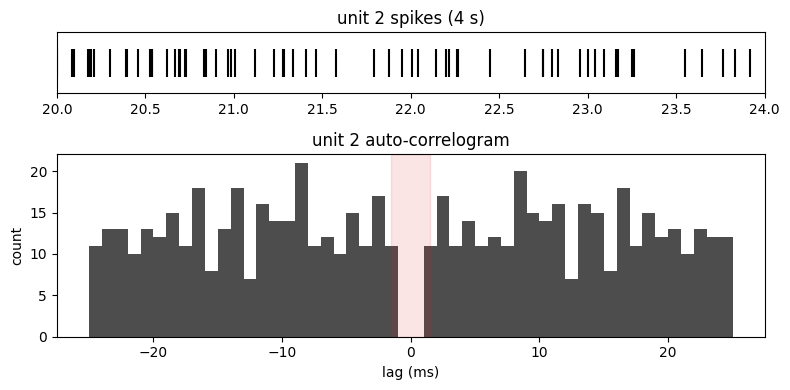

unit 2: refractory violations = 0.000


In [8]:
fig, ax = plt.subplots(2, 1, figsize=(8, 4), gridspec_kw={"height_ratios": [1, 3]})
ax[0].eventplot(t_u / fs, colors="k", lineoffsets=0, linelengths=1)
ax[0].set_xlim(20, 24); ax[0].set_yticks([]); ax[0].set_title(f"unit {u} spikes (4 s)")
c, n = correlogram(t_u, t_u, fs, bin_ms=1.0, exclude_zero=True)
ps.plotting.plot_correlogram(c, n, ax=ax[1], title=f"unit {u} auto-correlogram")
plt.tight_layout(); plt.show()
print(f"unit {u}: refractory violations = {ps.refractory_violations(t_u, fs):.3f}")

Unit `u` has the refractory hole — a single, clean neuron.

## 4. Catching an over-split

Real sorters often *over*-cluster on purpose and merge afterwards — splitting is easy to
undo, un-merging a true collision is not. Let's manufacture the classic mistake: split
unit `u` into two "units" by amplitude — its bigger spikes (**A**) and smaller spikes
(**B**), exactly what a too-eager clusterer would do. **First, the two spike trains:**

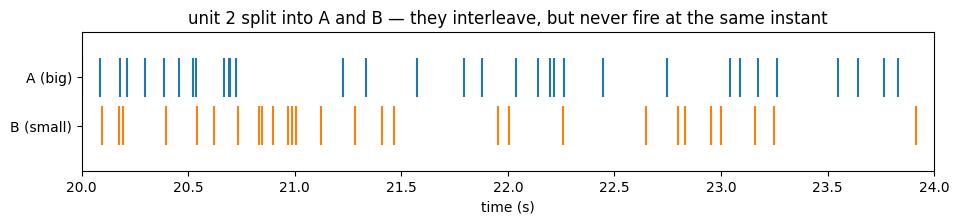

A: 442 spikes,  B: 441 spikes


In [9]:
snips, _ = ps.extract_snippets(filtered, t_u, align=False)
pc = ps.peak_channel(snips.mean(axis=0))
amp_u = snips[:, pc, :].max(axis=1) - snips[:, pc, :].min(axis=1)   # each spike's peak-channel size
med = np.median(amp_u)
tA, tB = t_u[amp_u >= med], t_u[amp_u < med]

plt.figure(figsize=(11, 1.8))
plt.eventplot([tB / fs, tA / fs], colors=["tab:orange", "tab:blue"], lineoffsets=[0, 1], linelengths=0.8)
plt.xlim(20, 24); plt.yticks([0, 1], ["B (small)", "A (big)"]); plt.xlabel("time (s)")
plt.title(f"unit {u} split into A and B — they interleave, but never fire at the same instant")
plt.show()
print(f"A: {len(tA)} spikes,  B: {len(tB)} spikes")

A and B ticks are never on top of each other — they can't be, being one neuron. The
**cross-correlogram** (A vs B) makes that quantitative: it inherits the **refractory
hole**. And because A and B are the same neuron, their **templates** are nearly
identical. The data behind both tests:

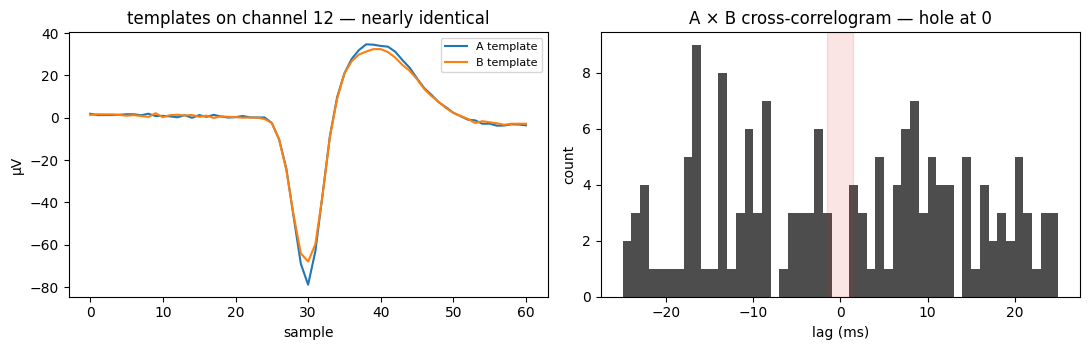

template similarity A vs B = 0.985  (near 1 -> same neuron -> MERGE)


In [10]:
cAB, nAB = correlogram(tA, tB, fs, bin_ms=1.0)
simAB = np.corrcoef(template_of(tA).ravel(), template_of(tB).ravel())[0, 1]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(template_of(tA)[pc], color="tab:blue", label="A template")
ax[0].plot(template_of(tB)[pc], color="tab:orange", label="B template")
ax[0].set_title(f"templates on channel {pc} — nearly identical"); ax[0].legend(fontsize=8)
ax[0].set_xlabel("sample"); ax[0].set_ylabel("µV")
ps.plotting.plot_correlogram(cAB, nAB, ax=ax[1], title="A × B cross-correlogram — hole at 0")
plt.tight_layout(); plt.show()
print(f"template similarity A vs B = {simAB:.3f}  (near 1 -> same neuron -> MERGE)")

Both tests agree — the cross-correlogram has the refractory hole and the templates lie on
top of each other. A and B are one neuron, over-split: **merge them.**

## 5. Don't over-merge: two genuinely different units

The same tests must say *no* for two *different* neurons. Take unit `u` and another unit
`u2`. **Again, start with the spike trains** — now unrelated, and they *do* occasionally
coincide (independent neurons fire together by chance):

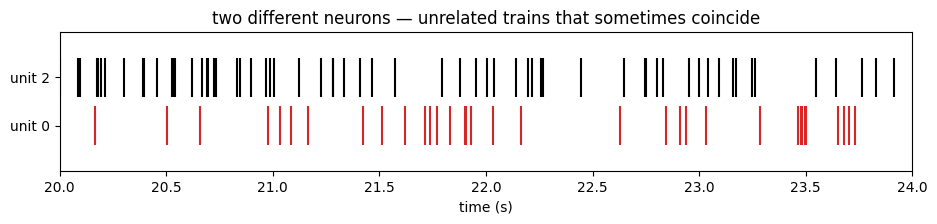

In [11]:
u2 = int([v for v in np.unique(labels) if v != u][0])
t_u2 = times[labels == u2]

plt.figure(figsize=(11, 1.8))
plt.eventplot([t_u2 / fs, t_u / fs], colors=["tab:red", "k"], lineoffsets=[0, 1], linelengths=0.8)
plt.xlim(20, 24); plt.yticks([0, 1], [f"unit {u2}", f"unit {u}"]); plt.xlabel("time (s)")
plt.title("two different neurons — unrelated trains that sometimes coincide")
plt.show()

**Exercise 2** *(~5 min)*. Compute the **template similarity** between units `u` and `u2`
(correlation of `template_of(t_u)` and `template_of(t_u2)`) and compare it to the A–B
value. The figure shows both templates and the A×B vs u×u2 cross-correlograms.

> **Check / unstuck.** A–B similarity ≈ 1 (merge); u–u2 similarity is much lower — often
> near 0 or negative (keep separate). Stuck? `np.corrcoef(x.ravel(), y.ravel())[0, 1]`.

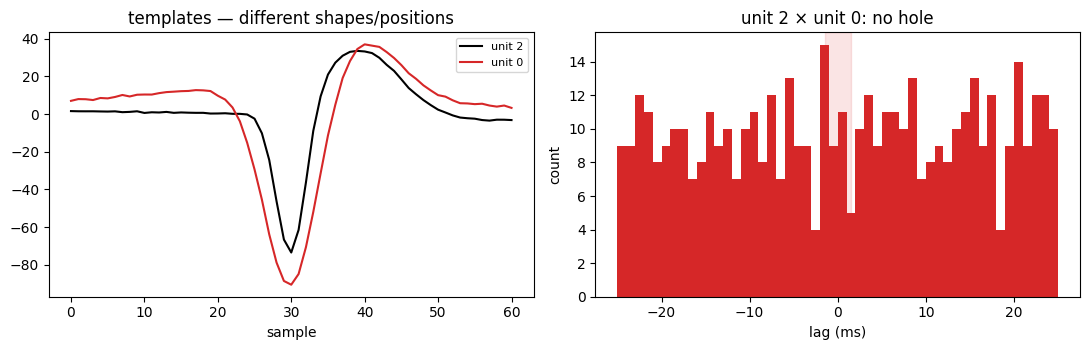

template similarity  A vs B          = 0.985  -> merge
template similarity  unit 2 vs unit 0 = -0.110  -> keep separate


In [12]:
sim_diff = np.corrcoef(template_of(t_u).ravel(), template_of(t_u2).ravel())[0, 1]
cD, nD = correlogram(t_u, t_u2, fs, bin_ms=1.0)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(template_of(t_u)[ps.peak_channel(template_of(t_u))], "k", label=f"unit {u}")
ax[0].plot(template_of(t_u2)[ps.peak_channel(template_of(t_u2))], "tab:red", label=f"unit {u2}")
ax[0].set_title("templates — different shapes/positions"); ax[0].legend(fontsize=8); ax[0].set_xlabel("sample")
ps.plotting.plot_correlogram(cD, nD, ax=ax[1], color="tab:red", title=f"unit {u} × unit {u2}: no hole")
plt.tight_layout(); plt.show()
print(f"template similarity  A vs B          = {simAB:.3f}  -> merge")
print(f"template similarity  unit {u} vs unit {u2} = {sim_diff:.3f}  -> keep separate")

The tests cleanly separate the cases: **merge when the templates match and the
cross-correlogram has a refractory hole; keep separate otherwise.** That is the logic
behind the manual **curation** every real spike-sorting pipeline still relies on — and,
increasingly, behind its automated merge steps.

## Wrap-up

Timing and shape statistics — the correlogram, the refractory period, template
similarity — let you audit a sort with no ground truth in sight: catch over-splits, merge
them, and flag contaminated units.

**Next (Notebook 8 — scoring):** the one thing we *can* do because our data is synthetic —
grade the whole sort against the truth.